## Setup & Data Transformations

Single source of truth for the data, feature columns, targets, model hyperparameters,
CV splitter, and bootstrap bookkeeping reused by every section.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.stats import kruskal, spearmanr
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import RFECV
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GroupKFold, cross_val_predict

In [ ]:
# Edits made 10/5/26.
# The change is to exclude zero abundant proteins found in the coronas formed on NPs from the dataset.

RANDOM_SEED = 1234

data_path = Path("") # Add path to dataset
excel_files = sorted(data_path.glob("*.xlsx"))
df = pd.read_excel(excel_files[0])

df = df[df["Abundance"] != 0].copy()

df.columns = (
    df.columns.str.lower()
    .str.replace(" ", "_")
    .str.replace("/", "_per_")
    .str.replace("(", "")
    .str.replace(")", "")
)

epsilon = df["abundance_controls"].drop_duplicates().nsmallest(2).iloc[-1]
print(epsilon)
df["abundance_controls"] = df["abundance_controls"].replace(0, epsilon)
df = df.assign(
    enriched=lambda d: np.where(d.abundance / d.abundance_controls > 1, 1, 0)
).assign(abundance_controls=lambda d: np.log2(d.abundance_controls.values))

target_column = "enriched"
not_features = ["entry", "sample_num", "abundance", "npunid", target_column]
feature_columns = [col for col in df.columns if col not in not_features]

proteins = df["entry"].reset_index(drop=True)
x = df.loc[:, feature_columns].reset_index(drop=True)
y = df.loc[:, target_column].reset_index(drop=True)
groups = proteins

print(
    f"n_samples={len(x)}, n_features={len(feature_columns)}, "
    f"n_proteins={groups.nunique()}, enriched_rate={y.mean():.3f}"
)

df.head(23)

0.000351715
n_samples=3171, n_features=84, n_proteins=369, enriched_rate=0.834


,entry,sample_num,abundance,abundance_controls,length,mass,frac_aa_a,frac_aa_c,frac_aa_d,frac_aa_e,...,ligand_citrate,ligand_pei,ligand_pvp,ligand_peg_five_k,dtem,dh_functionalized,centrifuged,np_incubation_concentration_mg_per_ml,incubation_concentration_mg_per_ml,enriched
0,Q3T149,32,0.020560,-11.473306,201,22393,0.084577,0.004975,0.039801,0.084577,...,0,0,0,0,200,221,1,4.0,40,1
3,P39873,42,0.014956,-11.473306,167,18450,0.053892,0.047904,0.029940,0.023952,...,1,0,0,0,82,151,0,5.0,40,1
4,Q27971,32,0.001950,-11.473306,700,79935,0.065714,0.020000,0.074286,0.090000,...,0,0,0,0,200,221,1,4.0,40,1
5,P01017,39,0.135422,-2.392052,476,51424,0.094538,0.006303,0.035714,0.046218,...,0,0,1,0,98,271,0,5.0,40,0
7,P37141,31,0.025321,-11.473306,0,0,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,200,221,1,4.0,4,1
9,Q6R8F2,45,0.002421,-11.473306,882,97938,0.062358,0.014739,0.077098,0.071429,...,0,0,0,1,244,609,0,5.0,40,1
10,A6QPQ2,37,0.006386,-5.555077,418,46964,0.055024,0.007177,0.055024,0.071770,...,0,0,1,0,182,316,0,5.0,40,0
11,Q27972,37,0.073003,-11.473306,0,0,0.000000,0.000000,0.000000,0.000000,...,0,0,1,0,182,316,0,5.0,40,1
13,P01017,31,0.305534,-2.392052,476,51424,0.094538,0.006303,0.035714,0.046218,...,0,0,0,0,200,221,1,4.0,4,1
15,P81187,43,0.109337,-2.669035,761,85366,0.052562,0.032852,0.059133,0.065703,...,0,1,0,0,82,288,0,5.0,40,0


In [4]:
# Shared RF hyperparameters (identical for classifier and regressor), CV splitter, and
# bootstrap constants used across every section.
rf_kwargs = dict(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
rf_reg_kwargs = dict(rf_kwargs)

N_FOLDS = 10
N_REPEATS = 10
N_BOOT = 500
TOP_K = 20

gkf = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)

# Cluster-bootstrap bookkeeping: resample whole protein groups, keeping within-protein
# correlation structure (matches the GroupKFold logic).
unique_groups = groups.unique()
group_to_idx = {g: np.flatnonzero(groups.values == g) for g in unique_groups}

In [5]:
# Regression targets. Row-level log1p target for in-sample Gini importance, and the true
# leave-one-NP-out setup with the three abundance transforms.
y_reg_full = np.log1p(df["abundance"].values)

y_loo_raw = df["abundance"].values
groups_loo = df["npunid"].values
unique_nps_loo = np.unique(groups_loo)

min_nonzero = y_loo_raw[y_loo_raw > 0].min()
floor_value = min_nonzero / 2
loo_transforms = {
    "log1p": (np.log1p, np.expm1),
    "asinh": (np.arcsinh, np.sinh),
    "log2_floor": (
        lambda v: np.log2(np.where(v == 0, floor_value, v)),
        lambda v: np.where(v <= np.log2(floor_value), 0.0, np.power(2.0, v)),
    ),
}

print(f"n_NPs={len(unique_nps_loo)}")

n_NPs=18


In [6]:
# Curated parsimonious feature sets. PARSI_7 is the 1-SD parsimonious set from the
# enrichment-classifier RFECV (below); PARSI_6 drops `ligand_pei`, which is highly
# collinear with `zeta_potential` (Spearman ~0.82), giving the final 6-feature model set.
PARSI_7 = [
    "abundance_controls",
    "secondary_structure_fraction_sheet",
    "zeta_potential",
    "ligand_pei",
    "nsp_secondary_structure_coil",
    "fraction_exposed_exposed_k",
    "frac_aa_a",
]
PARSI_6 = [f for f in PARSI_7 if f != "ligand_pei"]

missing = [f for f in PARSI_7 if f not in feature_columns]
assert not missing, f"missing feature columns: {missing}"

## Helpers

Reusable functions shared across sections: cluster-bootstrap importances, importance
summary + top-K plot, out-of-fold classifier metrics, and the PDP/ICE grid. Dedicated
RNGs keep the bootstrap resampling and the ICE row-subsample reproducible regardless of
run order.


In [7]:
# Dedicated generator so the cluster-bootstrap resampling is reproducible regardless of
# execution order. PDP/ICE plots subsample ICE_SUBSAMPLE rows via the estimator's own
# random_state (sklearn's `subsample` takes an int count, not an index array).
boot_rng = np.random.default_rng(RANDOM_SEED)  # cluster-bootstrap resampling
ICE_SUBSAMPLE = 200  # number of ICE curves drawn per PDP panel


def cluster_bootstrap_importances(
    make_estimator, y_vec, n_boot=N_BOOT, require_two_classes=False
):
    """Resample whole protein groups with replacement, refit, collect Gini importances.

    `make_estimator(seed)` returns a fresh unfitted model. Returns an
    (n_boot, n_features) DataFrame of feature importances.
    """
    out = np.empty((n_boot, len(feature_columns)), dtype=np.float64)
    collected = 0
    while collected < n_boot:
        sampled = boot_rng.choice(unique_groups, size=len(unique_groups), replace=True)
        idx = np.concatenate([group_to_idx[g] for g in sampled])
        yb = y_vec[idx]
        if require_two_classes and np.unique(yb).size < 2:
            continue  # degenerate resample; essentially never happens with this data
        model = make_estimator(RANDOM_SEED + collected).fit(x.iloc[idx], yb)
        out[collected] = model.feature_importances_
        collected += 1
        if collected % 100 == 0:
            print(f"  bootstrap {collected}/{n_boot}")
    return pd.DataFrame(out, columns=feature_columns)


def build_importance_summary(observed, boot_df):
    """Observed Gini importances + bootstrap mean and 95% percentile CI, sorted."""
    return pd.DataFrame(
        {
            "observed": observed,
            "boot_mean": boot_df.mean(),
            "ci_low": boot_df.quantile(0.025),
            "ci_high": boot_df.quantile(0.975),
        }
    ).sort_values("observed", ascending=False)


def plot_topk_importance(summary, color, xlabel, title, k=TOP_K):
    """Horizontal bar chart of the top-k features with bootstrap-CI error bars."""
    top = summary.head(k)
    err_low = (top["observed"] - top["ci_low"]).clip(lower=0)
    err_high = (top["ci_high"] - top["observed"]).clip(lower=0)
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(
        top.index[::-1],
        top["observed"][::-1],
        xerr=[err_low[::-1], err_high[::-1]],
        color=color,
        ecolor="black",
        capsize=3,
    )
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def oof_classifier_metrics(features, return_preds=False):
    """GroupKFold-by-protein out-of-fold metrics for an RF classifier on `features`."""
    proba = cross_val_predict(
        RandomForestClassifier(**rf_kwargs),
        x[features],
        y,
        cv=gkf,
        groups=groups,
        n_jobs=-1,
        method="predict_proba",
    )[:, 1]
    pred = (proba >= 0.5).astype(int)
    metrics = {
        "K": len(features),
        "roc_auc": roc_auc_score(y, proba),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
    }
    return (proba, pred, metrics) if return_preds else metrics


feature_labels = {
        "abundance_controls": "Protein Abundance in Serum",
        "zeta_potential": "Zeta Potential (mV)",
        "frac_aa_a": "% Alanine",
        "secondary_structure_fraction_sheet": "% Sheet-Associated Amino Acids",
        "nsp_secondary_structure_coil": "% Secondary Structure - Coil",
        "fraction_exposed_exposed_k": "Exposed Amino Acid Lysine / Total Exposed",
    }


def plot_pdp_ice(model, X, features, pd_color, title):
    """PDP (solid) + ICE (gray) grid for `features`, drawing ICE_SUBSAMPLE ICE curves."""
    ncols = (len(features) + 1) // 2
    fig, axes = plt.subplots(2, ncols, figsize=(16, 9))
    disp = PartialDependenceDisplay.from_estimator(
        model,
        X,
        features=features,
        kind="both",
        subsample=ICE_SUBSAMPLE,
        ice_lines_kw={"alpha": 0.15, "linewidth": 0.5, "color": "tab:gray"},
        pd_line_kw={"color": pd_color, "linewidth": 2.5},
        ax=axes.ravel()[: len(features)],
        random_state=RANDOM_SEED,
        
    )

    # Change y-axis labels
    for ax in disp.axes_.ravel():
        if ax is not None:
            ax.set_ylabel("Probability of protein enrichment")

            # Remove legend if present
            legend = ax.get_legend()
            if legend is not None:
                legend.remove()

    for ax, feature in zip(disp.axes_.ravel(), features):
        if ax is not None:
            ax.set_xlabel(feature_labels.get(feature, feature))
    fig.suptitle(title, y=1.01)
    plt.tight_layout()
    plt.show()


DATA_DIR = Path("data")  # CSV exports live in notebooks/data/
DATA_DIR.mkdir(exist_ok=True)


def export_csv(df, filename, index_name=None):
    """Save a result table to DATA_DIR/filename with no bare index column.

    `index_name` promotes a meaningful single-level index to a named column;
    a non-range index otherwise keeps its own name; a default RangeIndex is dropped.
    """
    out = df.copy()
    if index_name is not None:
        out = out.rename_axis(index_name).reset_index()
    elif not isinstance(out.index, pd.RangeIndex):
        out = out.reset_index()
    out.to_csv(DATA_DIR / filename, index=False)
    print(f"  {filename:48s} {out.shape[0]:>4d} x {out.shape[1]}")
    return DATA_DIR / filename


def export_shap_csv(shap_exp, stem):
    """Persist a SHAP Explanation so its beeswarm can be replotted without refitting.

    Writes two CSVs to DATA_DIR: `shap_{stem}_values.csv` (per-feature SHAP values, one
    row per sample) and `shap_{stem}_data.csv` (the matching feature values that color the
    beeswarm). Reload and replot with:
        v = pd.read_csv(DATA_DIR / f"shap_{stem}_values.csv")
        d = pd.read_csv(DATA_DIR / f"shap_{stem}_data.csv")
        exp = shap.Explanation(v.values, data=d.values, feature_names=list(v.columns))
        shap.plots.beeswarm(exp)
    """
    names = list(shap_exp.feature_names)
    export_csv(pd.DataFrame(shap_exp.values, columns=names), f"shap_{stem}_values.csv")
    export_csv(pd.DataFrame(shap_exp.data, columns=names), f"shap_{stem}_data.csv")

## RFR. Bootstrap Feature Importance

Cluster-bootstrap (resample protein groups, N=500) Gini importances for the abundance
regressor (`log1p` target) on the full feature set, with 95% percentile CIs, followed by
a Spearman correlation heatmap of the top-10 features.

In [8]:
# Single RF regressor fit on the full row-level data -> observed Gini importances.
rfr_full = RandomForestRegressor(**rf_reg_kwargs).fit(x, y_reg_full)
observed_importance_reg = pd.Series(
    rfr_full.feature_importances_, index=feature_columns, name="importance"
).sort_values(ascending=False)

observed_importance_reg.head(20).to_frame()

,importance
abundance_controls,0.639194
zeta_potential,0.024637
nsp_secondary_structure_helix,0.024050
nsp_secondary_structure_coil,0.021789
dh_functionalized,0.017322
frac_aa_m,0.009434
ligand_pei,0.008829
incubation_concentration_mg_per_ml,0.008609
fraction_exposed_exposed_a,0.008466
fraction_exposed_exposed_c,0.008239


In [9]:
# Cluster bootstrap by protein for the regressor (resample groups, refit, collect Gini).
boot_imp_reg_df = cluster_bootstrap_importances(
    lambda s: RandomForestRegressor(**{**rf_reg_kwargs, "random_state": s}),
    y_reg_full,
)
importance_summary_reg = build_importance_summary(
    observed_importance_reg, boot_imp_reg_df
)
importance_summary_reg.head(20)

  bootstrap 100/500
  bootstrap 200/500
  bootstrap 300/500
  bootstrap 400/500
  bootstrap 500/500


,observed,boot_mean,ci_low,ci_high
abundance_controls,0.639194,0.594322,0.354840,0.794347
zeta_potential,0.024637,0.032630,0.014216,0.063724
nsp_secondary_structure_helix,0.024050,0.005062,0.000634,0.023683
nsp_secondary_structure_coil,0.021789,0.004975,0.000608,0.024983
dh_functionalized,0.017322,0.017363,0.010911,0.027786
frac_aa_m,0.009434,0.004633,0.000583,0.018285
ligand_pei,0.008829,0.009740,0.002770,0.021556
incubation_concentration_mg_per_ml,0.008609,0.013514,0.006084,0.024997
fraction_exposed_exposed_a,0.008466,0.004498,0.000800,0.018452
fraction_exposed_exposed_c,0.008239,0.004110,0.000734,0.015762


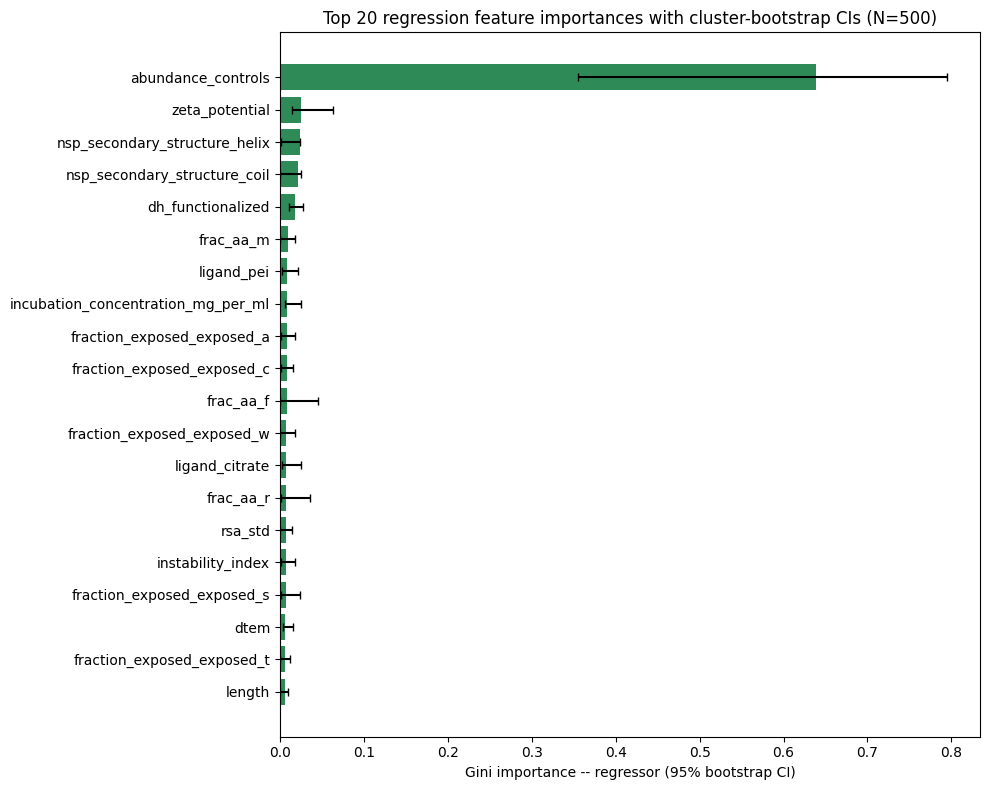

In [10]:
# Top-K regression importances with 95% bootstrap CI as error bars.
plot_topk_importance(
    importance_summary_reg,
    color="seagreen",
    xlabel="Gini importance -- regressor (95% bootstrap CI)",
    title=f"Top {TOP_K} regression feature importances with cluster-bootstrap CIs (N={N_BOOT})",
)

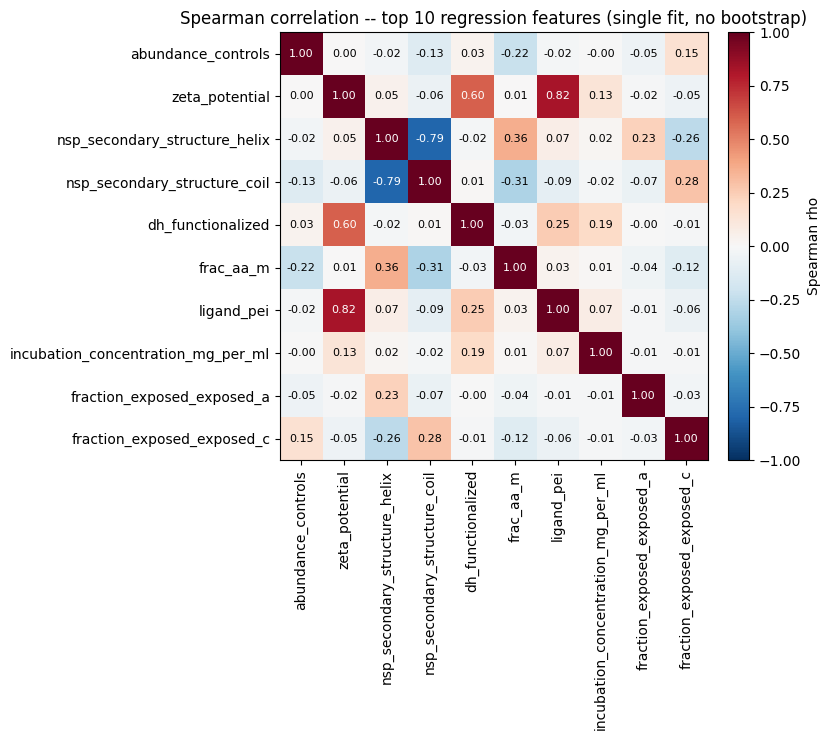

,abundance_controls,zeta_potential,nsp_secondary_structure_helix,nsp_secondary_structure_coil,dh_functionalized,frac_aa_m,ligand_pei,incubation_concentration_mg_per_ml,fraction_exposed_exposed_a,fraction_exposed_exposed_c
abundance_controls,1.000,0.001,-0.025,-0.131,0.034,-0.222,-0.016,-0.005,-0.052,0.149
zeta_potential,0.001,1.000,0.046,-0.060,0.595,0.005,0.822,0.125,-0.015,-0.051
nsp_secondary_structure_helix,-0.025,0.046,1.000,-0.793,-0.022,0.360,0.069,0.017,0.233,-0.258
nsp_secondary_structure_coil,-0.131,-0.060,-0.793,1.000,0.014,-0.311,-0.086,-0.016,-0.065,0.283
dh_functionalized,0.034,0.595,-0.022,0.014,1.000,-0.030,0.251,0.188,-0.001,-0.009
frac_aa_m,-0.222,0.005,0.360,-0.311,-0.030,1.000,0.031,0.009,-0.041,-0.118
ligand_pei,-0.016,0.822,0.069,-0.086,0.251,0.031,1.000,0.072,-0.013,-0.059
incubation_concentration_mg_per_ml,-0.005,0.125,0.017,-0.016,0.188,0.009,0.072,1.000,-0.009,-0.011
fraction_exposed_exposed_a,-0.052,-0.015,0.233,-0.065,-0.001,-0.041,-0.013,-0.009,1.000,-0.028
fraction_exposed_exposed_c,0.149,-0.051,-0.258,0.283,-0.009,-0.118,-0.059,-0.011,-0.028,1.000


In [11]:
# Spearman correlation among the top 10 features by single-fit regressor Gini importance.
top10_reg_feats = observed_importance_reg.head(10).index.tolist()
corr_reg = x[top10_reg_feats].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(corr_reg.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(top10_reg_feats)))
ax.set_xticklabels(top10_reg_feats, rotation=90)
ax.set_yticks(range(len(top10_reg_feats)))
ax.set_yticklabels(top10_reg_feats)
for i in range(len(top10_reg_feats)):
    for j in range(len(top10_reg_feats)):
        v = corr_reg.values[i, j]
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            color="white" if abs(v) > 0.5 else "black",
            fontsize=8,
        )
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Spearman rho")
ax.set_title(
    "Spearman correlation -- top 10 regression features (single fit, no bootstrap)"
)
plt.tight_layout()
plt.show()
corr_reg.round(3)

## RFC. Bootstrap Feature Importance

Cluster-bootstrap (N=500) Gini importances for the enrichment classifier on the full
feature set, with 95% percentile CIs.

In [12]:
# Baseline: single RF fit on full data to get observed Gini importances.
rfc_full = RandomForestClassifier(**rf_kwargs).fit(x, y)
observed_importance = pd.Series(
    rfc_full.feature_importances_, index=feature_columns, name="importance"
).sort_values(ascending=False)

observed_importance.head(20).to_frame()

,importance
abundance_controls,0.191281
nsp_secondary_structure_sheet,0.025583
fraction_exposed_nonpolar_exposed,0.025000
fraction_exposed_polar_exposed,0.022654
flexibility_min,0.021221
fraction_exposed_exposed_m,0.020794
fraction_exposed_exposed_y,0.020402
asa_sum,0.019982
frac_aa_m,0.019569
fraction_exposed_exposed_t,0.018015


In [13]:
# Cluster bootstrap by protein for the classifier (resample groups, refit, collect Gini).
boot_imp_df = cluster_bootstrap_importances(
    lambda s: RandomForestClassifier(**{**rf_kwargs, "random_state": s}),
    y.values,
    require_two_classes=True,
)
importance_summary_clf = build_importance_summary(observed_importance, boot_imp_df)
importance_summary_clf.head(20)

  bootstrap 100/500
  bootstrap 200/500
  bootstrap 300/500
  bootstrap 400/500
  bootstrap 500/500


,observed,boot_mean,ci_low,ci_high
abundance_controls,0.191281,0.161841,0.121298,0.212404
nsp_secondary_structure_sheet,0.025583,0.025957,0.009139,0.049644
fraction_exposed_nonpolar_exposed,0.025000,0.020108,0.007092,0.041214
fraction_exposed_polar_exposed,0.022654,0.019986,0.005715,0.041990
flexibility_min,0.021221,0.021544,0.007051,0.048267
fraction_exposed_exposed_m,0.020794,0.019570,0.006086,0.042060
fraction_exposed_exposed_y,0.020402,0.017777,0.005582,0.038116
asa_sum,0.019982,0.014354,0.006003,0.028235
frac_aa_m,0.019569,0.015119,0.005059,0.031019
fraction_exposed_exposed_t,0.018015,0.014765,0.005258,0.032800


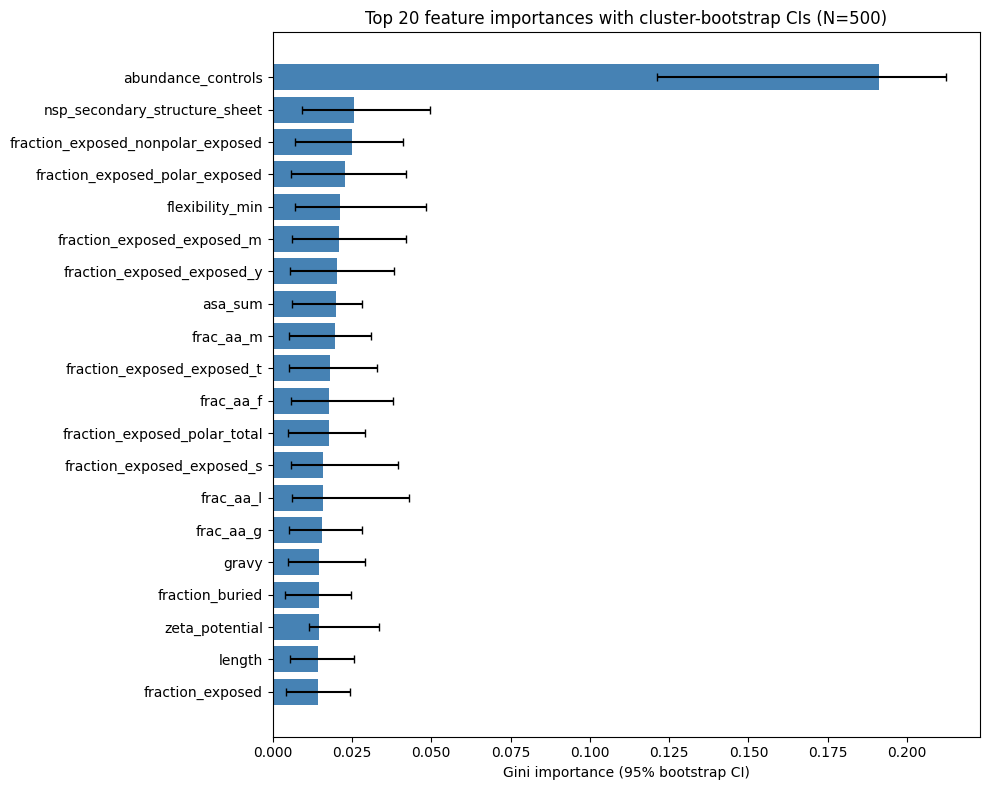

In [14]:
# Top-K classifier importances with 95% bootstrap CI as error bars.
plot_topk_importance(
    importance_summary_clf,
    color="steelblue",
    xlabel="Gini importance (95% bootstrap CI)",
    title=f"Top {TOP_K} feature importances with cluster-bootstrap CIs (N={N_BOOT})",
)

Can save the above outputs to either .csv of.xlsx to see the full list of feature importance values and summary tables.